# Y3_mock_imweights: dust, CIB and CMB lensing. Summary of the tests

This notebook only **reads the outputs saved by the scripts** in this folder and plots them (it runs in seconds). To refresh a number, rerun the script named at the top of the section, then rerun this notebook.

## The two points these tests make

**A. For Euclid: an extinction map built from dust emission carries CIB, and that is what correlates with galaxies.**
SFD, like the Planck E(B−V) template Euclid uses, is built from far-IR dust emission. Far-IR emission includes the cosmic infrared background (CIB), which traces the same large-scale structure as the galaxies.
* SFD correlates with an independent CIB map (Lenz+19), r ≈ +0.25 at 857 GHz.
* The galaxy × SFD correlation equals the CIB-route prediction r(g, CIB)·r(CIB, SFD) for every LRG sample (measured/predicted 0.85–1.03, χ²/n < 1). This is the same test, and the same result, as in Euclid's 857 GHz analysis (C. Daley, CMBX KP2-3, 22 Oct 2026, slide 13).
* CSFD (Chiang 2023), which removes the galaxy-traced CIB from SFD, shows **no** galaxy correlation (r ≈ 0) and no κ correlation.

So a tracer × extinction correlation is expected from the template's CIB, not from a problem in the galaxy or shear catalogs. A CIB-cleaned map such as CSFD is the fix.

**B. For DESI: our imaging weights do not remove CMB-lensing signal.**
* Photo baseline (CSFD + HI): Cgκ is unchanged when SFD is used instead of CSFD (≤ 0.5%, ≤ 0.07σ per bin).
* Spec DESI default: changing its EBV_DIFF dust maps moves Cgκ by ≈ 1% (≤ 0.2σ per bin).
* The one dangerous choice, fitting SFD **and** CSFD together, removes 46–73% of Cgκ. It is identified and never used.
* The mode removal the weights cause on mocks (no systematics injected) is measured and corrected for.

| § | Question | Script → output | Answer |
|---|---|---|---|
| A1 | Do SFD / CSFD contain CIB? | `cib_check.py` → `figures/cib_check.txt` | SFD r ≈ +0.25, CSFD ≈ +0.17 (857 GHz); HI control ≈ 0 |
| A2 | Is galaxy × SFD the CIB? (Euclid test) | `euclid_data_check.py` → `figures/euclid_data_*.txt` | LRG: yes (ratio ≈ 1); BGS: 2× above; QSO: below. CSFD: no galaxy correlation |
| A3 | Is κ × SFD the CIB? | `cib_check.py`, `dust_map_check.py` | κ × SFD small (r ≲ 0.05–0.1), at or below its CIB route; κ × CSFD ≈ 0 |
| A4 | What did CSFD remove? (D = CSFD − SFD) | both | The galaxy-traced CIB: r(D, κ) ≈ −0.5, r(D, g) ≈ −0.2 to −0.3, between its two reference models (CIB route → projection) |
| B1 | Does the dust choice in our weights change Cgκ on data? | `regress_*_data.py`, `compare_data_variants.py` | No (photo ≤ 0.5%, spec ≈ 1%); only CSFD+SFD together does (−46 to −73%) |
| B2 | How much clustering do the weights remove on mocks? | `regress_*_mocks.py`, `compare_variants.py` | Photo ~20% at ℓ = 2–5, < 1% at ℓ ≳ 30; spec much milder |

**Notation**
* **r_ℓ(A, B) = C_ℓ^{AB} / sqrt(C_ℓ^{AA} C_ℓ^{BB})**: correlation coefficient per ℓ bin (nside-256 pseudo-C_ℓ, fsky-corrected, on the stated common footprint), in [−1, 1]. The grey bands are ±1/sqrt(N_modes), its scatter for unrelated maps.
* **CIB route** (the Euclid test): if a template X = dust + α·CIB and the dust does not correlate with the tracer t, then r(t, X) = r(t, CIB)·r(CIB, X) band by band, with nothing fitted. The CIB auto-spectrum is the odd × even half-ring cross, which is noise-free (as in Euclid).
* **D = CSFD − SFD**: minus the LSS/CIB component CSFD subtracts from SFD.

In [1]:
import glob, os, re
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = "/global/cfs/cdirs/desicollab/users/schiarenza/Y3_mock_imweights"
FIG = os.path.join(ROOT, "figures")
# categorical palette (validated, fixed order; dataviz default instance)
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "0.9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2, "lines.markersize": 5, "legend.frameon": False, "legend.fontsize": 8,
    "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
})
RANGE = re.compile(r"\d+-\d+$")


def read_tables(path):
    # Parse the r_ell tables written by dust_map_check / cib_check / euclid_data_check.
    # Returns {(section, subsection): {"bins": (n,2) array, "meta": str, "rows": {label: values}}}.
    # Sections are the '==' lines, subsections the '--' lines (text before ':').
    # Rows labelled 'via CIB ...' are renamed '<previous measured label> via CIB'.
    out, sec, sub, meta, bins, last = {}, "", "", "", None, ""
    for line in open(path):
        st = line.strip()
        if st.startswith("=="):
            sec, sub, meta = st.strip("= ").split(":")[0].strip(), "", st
            continue
        if st.startswith("--"):
            sub, meta = st[2:].split(":")[0].strip(), st
            continue
        toks = st.split()
        if len(toks) >= 3 and all(RANGE.match(t) for t in toks[-3:]):
            bins = np.array([[int(x) for x in t.split("-")] for t in toks if RANGE.match(t)])
            continue
        vals = []
        for t in reversed(toks):
            try:
                vals.append(float(t))
            except ValueError:
                break
        if len(vals) < 5 or bins is None:
            continue
        label = " ".join(toks[: len(toks) - len(vals)])
        if label.startswith("via CIB") and last.endswith("measured"):
            label = last.replace(" measured", " via CIB")
        last = label
        d = out.setdefault((sec, sub), {"bins": bins, "meta": meta, "rows": {}})
        d["rows"][label] = np.array(vals[::-1])[: len(bins)]
    return out


def ell_centres(bins):
    return 0.5 * (bins[:, 0] + bins[:, 1])


def fsky_of(meta):
    m = re.search(r"fsky=([\d.]+)", meta)
    return float(m.group(1)) if m else None


def noise_band(ax, bins, fsky):
    # +-1/sqrt(N_modes) per bin: the scatter of r_ell for two uncorrelated maps.
    lc, dl = ell_centres(bins), bins[:, 1] - bins[:, 0]
    sig = 1 / np.sqrt((2 * lc + 1) * dl * fsky)
    ax.fill_between(lc, -sig, sig, color="0.88", lw=0, label=r"$\pm 1/\sqrt{N_{\rm modes}}$")


def finish(ax, ylabel=None, xlabel=r"multipole $\ell$", log=True):
    ax.axhline(0, color="0.4", lw=0.8)
    if log:
        ax.set_xscale("log")
    ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)

In [2]:
def euclid_rows(s, T, cibkey="CIB 857 GHz, 2.5e+20_gp20"):
    e = read_tables(os.path.join(FIG, f"euclid_data_{s}_{T}.txt"))[(cibkey, "")]
    return e["bins"], e["rows"], fsky_of(e["meta"])

def route_stats(meas, pred, bins, fsky, lmin=92):
    # Euclid-style summary over ell >= lmin: inverse-variance projection of measured on predicted, chi2/n vs predicted
    hi = bins[:, 0] >= lmin
    lc, dl = ell_centres(bins)[hi], (bins[:, 1] - bins[:, 0])[hi]
    w = (2 * lc + 1) * dl * fsky  # 1/sigma^2 per bin, sigma = 1/sqrt(N_modes)
    m, p = meas[hi], pred[hi]
    return (m * p * w).sum() / (p * p * w).sum(), ((m - p) ** 2 * w).mean(), m.mean(), p.mean()

TRACERS = [("photo", t) for t in ("BGS", "LRG1", "LRG2", "LRG3")] + [("spec", t) for t in ("BGS", "LRG1", "LRG2", "LRG3", "QSO", "QSO1", "QSO2")]
cib = read_tables(os.path.join(FIG, "cib_check.txt"))
FOOT = "CIB & photo & CSFD-cosmo"
CIBMAPS = [k[0] for k in cib if k[1] == FOOT]
M857 = next(m for m in CIBMAPS if m.startswith("857") and "2.5e" in m)
maps, m857 = CIBMAPS, M857  # names used by the reused D x kappa cell

# Part A. For Euclid: the extinction × galaxy correlation is CIB in the template

## A1. SFD and CSFD contain CIB (HI does not)
*Script:* `cib_check.py` → `figures/cib_check.txt`. *Footprint:* Lenz CIB mask ∩ DESI photo footprint ∩ CSFD cosmology mask (fsky ≈ 0.15).
*CIB maps:* Lenz, Doré & Lagache (2019): Planck HFI minus an HI-based dust model, with **no galaxies** involved. 353, 545 and 857 GHz on the N_HI < 2.5×10²⁰ cm⁻² mask, and 857 GHz on N_HI < 4×10²⁰.

**What is plotted:** r_ℓ(X, CIB) for X = SFD (solid) and CSFD (dashed), one colour per CIB map. HI (dotted) is a control: the Lenz maps are HI-cleaned, so it should be ≈ 0.

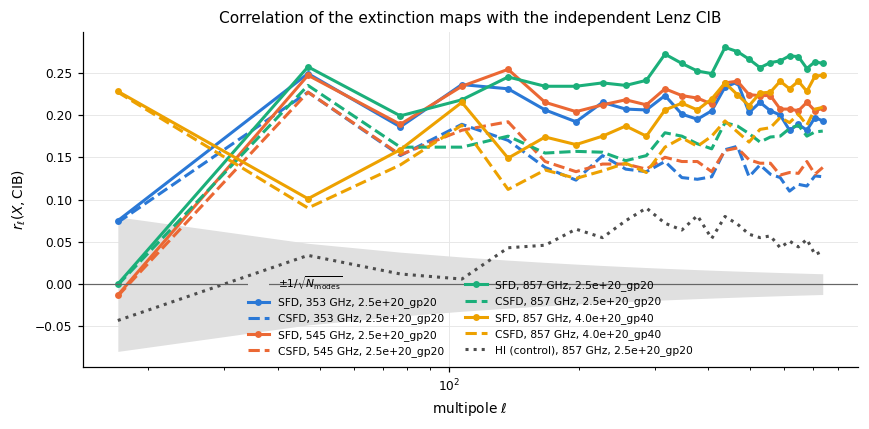

**Mean over ℓ ≥ 92**

| CIB map | r(SFD, CIB) | r(CSFD, CIB) | r(HI, CIB) |
|---|---|---|---|
| 353 GHz, 2.5e+20_gp20 | +0.21 | +0.14 | +0.06 |
| 545 GHz, 2.5e+20_gp20 | +0.22 | +0.15 | +0.06 |
| 857 GHz, 2.5e+20_gp20 | +0.25 | +0.17 | +0.06 |
| 857 GHz, 4.0e+20_gp40 | +0.21 | +0.17 | +0.05 |

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
d0 = cib[(CIBMAPS[0], FOOT)]
noise_band(ax, d0["bins"], fsky_of(d0["meta"]))
for i, m in enumerate(CIBMAPS):
    d = cib[(m, FOOT)]; lc = ell_centres(d["bins"])
    ax.plot(lc, d["rows"]["r(SFD, CIB)"], marker="o", ms=3.5, color=PAL[i], label=f"SFD, {m}")
    ax.plot(lc, d["rows"]["r(CSFD, CIB)"], "--", color=PAL[i], label=f"CSFD, {m}")
d = cib[(M857, FOOT)]
ax.plot(ell_centres(d["bins"]), d["rows"]["r(HI, CIB)"], ":", color="0.3", label=f"HI (control), {M857}")
ax.set_title("Correlation of the extinction maps with the independent Lenz CIB")
finish(ax, r"$r_\ell(X, {\rm CIB})$"); ax.legend(ncol=2, fontsize=7)
plt.tight_layout(); plt.show()
rows = []
for m in CIBMAPS:
    d = cib[(m, FOOT)]; hi = d["bins"][:, 0] >= 92
    rows.append(f"| {m} | {d['rows']['r(SFD, CIB)'][hi].mean():+.2f} | {d['rows']['r(CSFD, CIB)'][hi].mean():+.2f} | {d['rows']['r(HI, CIB)'][hi].mean():+.2f} |")
display(Markdown("**Mean over ℓ ≥ 92**\n\n| CIB map | r(SFD, CIB) | r(CSFD, CIB) | r(HI, CIB) |\n|---|---|---|---|\n" + "\n".join(rows)))

**Result.** SFD correlates with the CIB at r ≈ +0.2–0.28 for ℓ ≳ 90, strongest at 857 GHz (as for Euclid's template). CSFD still correlates at ≈ +0.13–0.19: it removes the CIB that traces galaxies, not all of it (A2 shows what is left does not correlate with our galaxies). The HI control is ≈ 0.

## A2. The Euclid test on DESI galaxies: galaxy × SFD is the CIB
*Script:* `euclid_data_check.py` → `figures/euclid_data_<sample>_<T>.{txt,png}`. *Galaxies:* real DESI catalogs, δ_g weighted by the analysis weight **without** the imaging weight ("raw", i.e. the sample's actual correlation with dust). *Footprint:* data mask ∩ CIB mask.

**What is plotted** (one panel per sample, CIB 857 GHz, N_HI < 2.5e20):
* **blue points:** measured r(δ_g, SFD); **blue line:** its CIB route r(δ_g, CIB)·r(CIB, SFD);
* **aqua points / line:** the same for CSFD;
* **grey dashed:** r(δ_g, CIB) itself.

Points on their line mean the galaxy–template correlation is entirely the template's CIB.

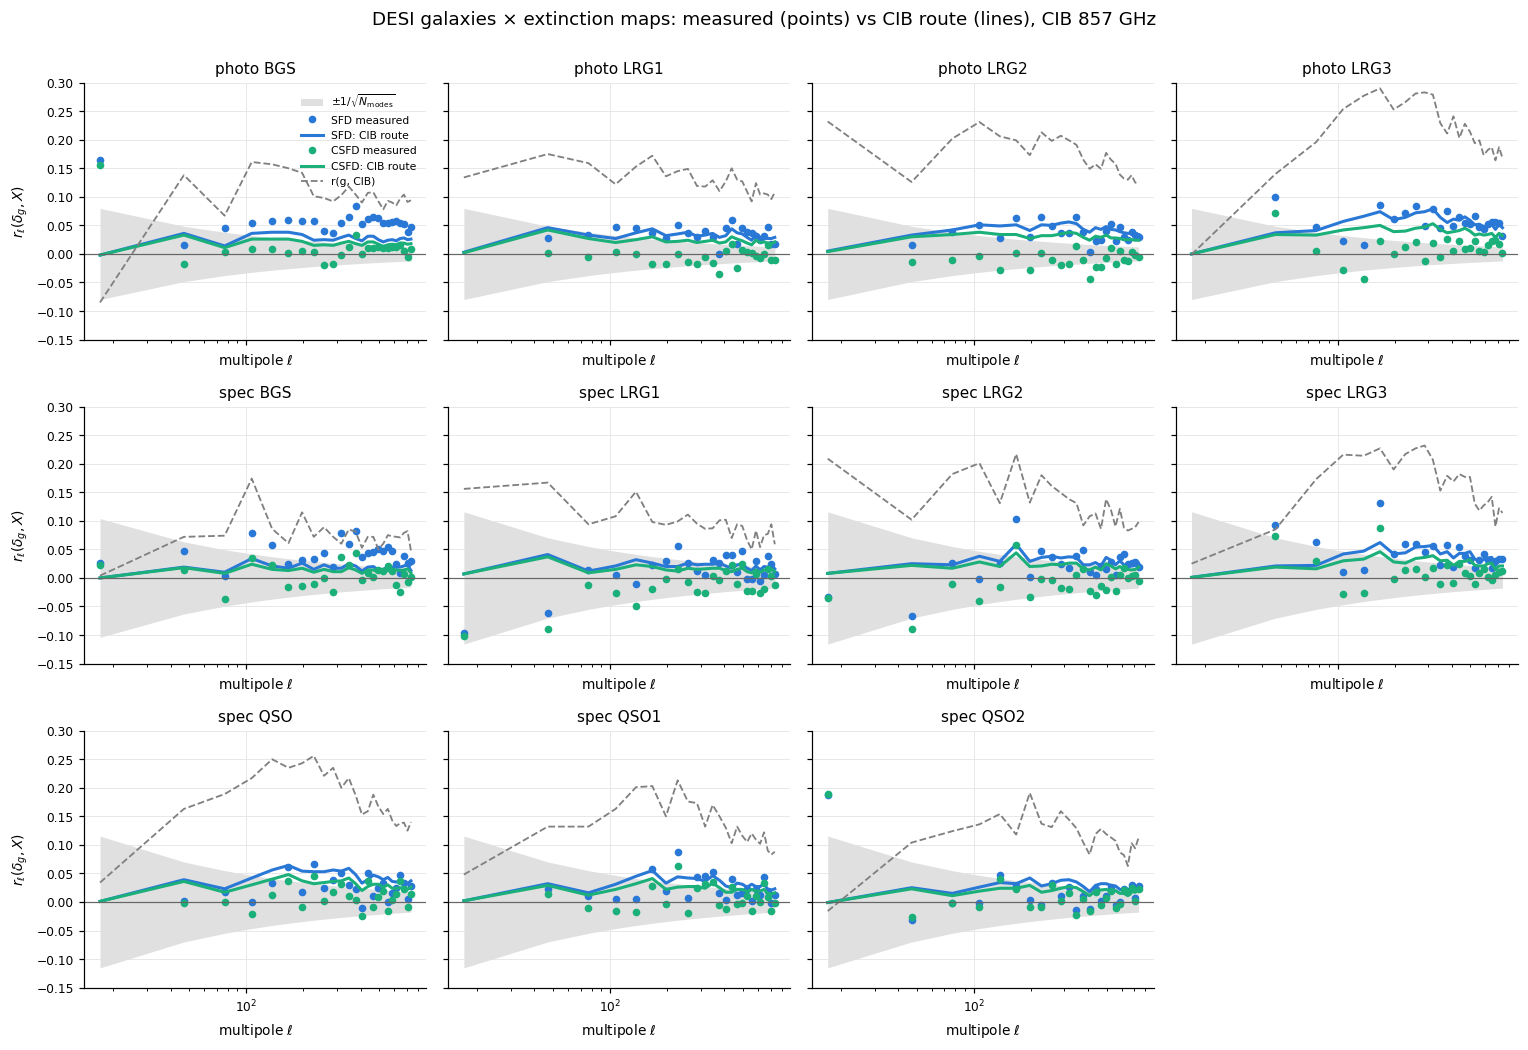

**ℓ ≥ 92, CIB 857 GHz.** ratio = inverse-variance projection of measured on predicted (as on the Euclid slide); χ²/n of measured vs the CIB route with σ = 1/sqrt(N_modes).

| sample | r(g,SFD) measured | CIB route | ratio | χ²/n | r(g,CSFD) measured | CSFD CIB route |
|---|---|---|---|---|---|---|
| photo BGS | +0.056 | +0.028 | **2.03** | 3.34 | +0.006 | +0.019 |
| photo LRG1 | +0.034 | +0.033 | **1.03** | 0.62 | -0.006 | +0.022 |
| photo LRG2 | +0.038 | +0.044 | **0.85** | 0.72 | -0.010 | +0.030 |
| photo LRG3 | +0.055 | +0.059 | **0.97** | 0.65 | +0.008 | +0.040 |
| spec BGS | +0.044 | +0.020 | **2.12** | 1.79 | +0.006 | +0.013 |
| spec LRG1 | +0.020 | +0.021 | **0.99** | 0.49 | -0.007 | +0.015 |
| spec LRG2 | +0.028 | +0.030 | **0.95** | 0.40 | -0.006 | +0.021 |
| spec LRG3 | +0.040 | +0.041 | **0.97** | 0.40 | +0.007 | +0.028 |
| spec QSO | +0.028 | +0.045 | **0.62** | 0.98 | +0.010 | +0.031 |
| spec QSO1 | +0.025 | +0.034 | **0.76** | 0.61 | +0.007 | +0.023 |
| spec QSO2 | +0.013 | +0.029 | **0.47** | 0.79 | +0.007 | +0.020 |

In [4]:
fig, axes = plt.subplots(3, 4, figsize=(14, 9.5), sharex=True, sharey=True)
for ax, (s, T) in zip(axes.flat, TRACERS):
    bins, rows, fsky = euclid_rows(s, T)
    lc = ell_centres(bins)
    noise_band(ax, bins, fsky)
    for x, c in (("SFD", PAL[0]), ("CSFD", PAL[2])):
        ax.plot(lc, rows[f"r(g_raw, {x}) measured"], "o", ms=4, color=c, label=f"{x} measured")
        ax.plot(lc, rows[f"r(g_raw, {x}) via CIB"], color=c, label=f"{x}: CIB route")
    ax.plot(lc, rows["r(g_raw, CIB)"], "--", lw=1.2, color="0.5", label="r(g, CIB)")
    ax.set_title(f"{s} {T}"); ax.set_ylim(-0.15, 0.3)
    finish(ax)
axes.flat[-1].axis("off")
axes[0, 0].legend(fontsize=7)
for ax in axes[:, 0]:
    ax.set_ylabel(r"$r_\ell(\delta_g, X)$")
plt.suptitle("DESI galaxies × extinction maps: measured (points) vs CIB route (lines), CIB 857 GHz", y=1.0)
plt.tight_layout(); plt.show()

rows_md = []
for s, T in TRACERS:
    bins, rows, fsky = euclid_rows(s, T)
    ratio, chi2, m, p = route_stats(rows["r(g_raw, SFD) measured"], rows["r(g_raw, SFD) via CIB"], bins, fsky)
    _, _, cm, cp = route_stats(rows["r(g_raw, CSFD) measured"], rows["r(g_raw, CSFD) via CIB"], bins, fsky)
    rows_md.append(f"| {s} {T} | {m:+.3f} | {p:+.3f} | **{ratio:.2f}** | {chi2:.2f} | {cm:+.3f} | {cp:+.3f} |")
display(Markdown("**ℓ ≥ 92, CIB 857 GHz.** ratio = inverse-variance projection of measured on predicted (as on the Euclid slide); χ²/n of measured vs the CIB route with σ = 1/sqrt(N_modes).\n\n"
                 "| sample | r(g,SFD) measured | CIB route | ratio | χ²/n | r(g,CSFD) measured | CSFD CIB route |\n|---|---|---|---|---|---|---|\n" + "\n".join(rows_md)))

**Frequency dependence (as on the Euclid slide).** The lower-frequency CIB maps trace slightly different CIB, so the SFD prediction drops and measured/predicted rises from 857 to 353 GHz. That is the pattern Euclid sees, consistent with a dust-emission template whose CIB looks most like the 857 GHz CIB.

In [5]:
rows_md = []
for s, T in TRACERS:
    cells = []
    for m in CIBMAPS:
        bins, rows, fsky = euclid_rows(s, T, f"CIB {m}")
        ratio, chi2, _, _ = route_stats(rows["r(g_raw, SFD) measured"], rows["r(g_raw, SFD) via CIB"], bins, fsky)
        cells.append(f"{ratio:.2f} ({chi2:.1f})")
    rows_md.append(f"| {s} {T} | " + " | ".join(cells) + " |")
display(Markdown("**SFD measured/predicted (χ²/n), ℓ ≥ 92, per CIB map**\n\n| sample | " + " | ".join(CIBMAPS) + " |\n|---|" + "---|" * len(CIBMAPS) + "\n" + "\n".join(rows_md)))

**SFD measured/predicted (χ²/n), ℓ ≥ 92, per CIB map**

| sample | 353 GHz, 2.5e+20_gp20 | 545 GHz, 2.5e+20_gp20 | 857 GHz, 2.5e+20_gp20 | 857 GHz, 4.0e+20_gp40 |
|---|---|---|---|---|
| photo BGS | 3.47 (7.9) | 3.52 (7.6) | 2.03 (3.3) | 0.85 (0.7) |
| photo LRG1 | 2.10 (2.1) | 1.76 (1.5) | 1.03 (0.6) | 1.29 (1.0) |
| photo LRG2 | 1.78 (1.9) | 1.48 (1.3) | 0.85 (0.7) | 0.90 (0.8) |
| photo LRG3 | 1.79 (3.4) | 1.45 (2.0) | 0.97 (0.7) | 0.86 (1.1) |
| spec BGS | 3.29 (3.1) | 3.38 (3.1) | 2.12 (1.8) | 1.07 (0.5) |
| spec LRG1 | 2.19 (1.1) | 1.93 (0.8) | 0.99 (0.5) | 1.28 (0.7) |
| spec LRG2 | 1.91 (1.0) | 1.56 (0.8) | 0.95 (0.4) | 1.00 (0.5) |
| spec LRG3 | 1.73 (1.1) | 1.48 (0.8) | 0.97 (0.4) | 0.64 (1.3) |
| spec QSO | 0.87 (0.5) | 0.70 (0.7) | 0.62 (1.0) | 0.22 (2.9) |
| spec QSO1 | 1.11 (0.5) | 0.89 (0.6) | 0.76 (0.6) | 0.39 (1.3) |
| spec QSO2 | 0.62 (0.4) | 0.51 (0.6) | 0.47 (0.8) | 0.02 (2.0) |

**Result.**
* **LRG (photo and spec, 6 samples): galaxy × SFD is the CIB.** Measured/predicted is 0.85–1.03 at 857 GHz with χ²/n = 0.4–0.7. This is the same conclusion as Euclid's for their extinction template.
* **Frequency trend, as in Euclid:** for LRG, measured/predicted rises from ≈ 1.0 (857 GHz) to 1.5–1.9 (545) and 1.7–2.2 (353). Euclid's δ₅ went 1.26 → 1.63 → 1.89. The CIB in a dust-emission extinction map looks most like the 857 GHz CIB, which fits how SFD and Planck E(B−V) are built (100 μm / 857 GHz dust emission).
* **BGS:** about 2× above the CIB route on the N_HI < 2.5e20 mask (χ²/n 1.8–3.3, with or without our imaging weights), but 0.85–1.07 on the larger 857 GHz N_HI < 4e20 mask. So the BGS excess is not robust across footprints. Where present, it lies in the D = CSFD − SFD direction (A4).
* **QSO:** below the CIB route (0.5–0.8). The high-z quasars correlate with SFD less than its CIB content would suggest. Harmless.
* **CSFD: r(g, CSFD) ≈ 0 for every sample**, although CSFD still correlates with the CIB (A1). The CIB that CSFD leaves in does not trace our galaxies. **CSFD is the clean template.**

## A3. CMB lensing: κ × SFD and κ × CSFD
*Scripts:* `cib_check.py` (CIB route) and `dust_map_check.py` (photo footprint ∩ lensing mask).

**What is plotted:** measured r(X, κ) (points) and its CIB route r(X, CIB)·r(CIB, κ) (lines) for X = SFD and CSFD, at 857 GHz, for Planck PR4 and ACT DR6.

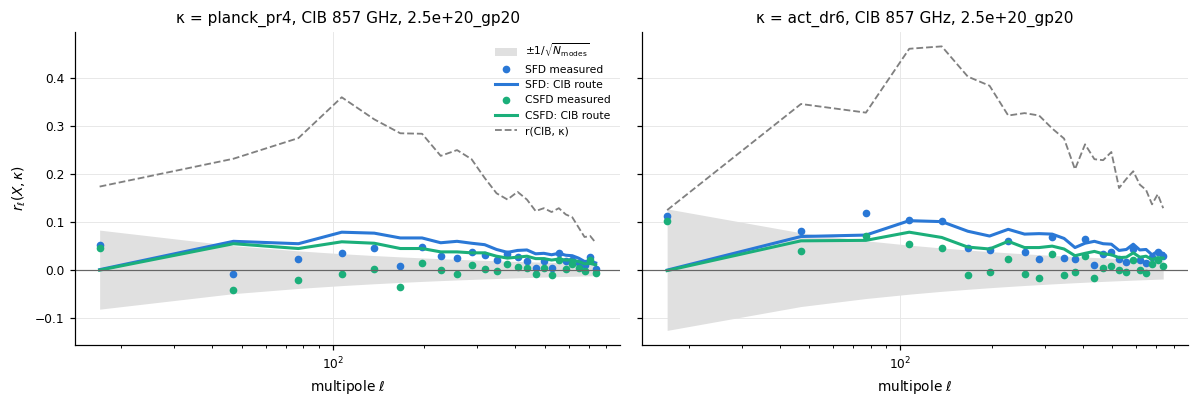

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, lens in zip(axes, ("planck_pr4", "act_dr6")):
    d = cib[(M857, f"{lens} x CIB {M857}")]
    lc = ell_centres(d["bins"])
    noise_band(ax, d["bins"], fsky_of(d["meta"]))
    for x, c in (("SFD", PAL[0]), ("CSFD", PAL[2])):
        if f"r({x}, kappa) measured" not in d["rows"]:
            continue
        ax.plot(lc, d["rows"][f"r({x}, kappa) measured"], "o", ms=4, color=c, label=f"{x} measured")
        ax.plot(lc, d["rows"][f"r({x},CIB) r(CIB,kappa)"], color=c, label=f"{x}: CIB route")
    ax.plot(lc, d["rows"]["r(CIB, kappa)"], "--", lw=1.2, color="0.5", label="r(CIB, κ)")
    ax.set_title(f"κ = {lens}, CIB {M857}")
    finish(ax, r"$r_\ell(X,\kappa)$" if lens == "planck_pr4" else None)
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Result.**
* κ × SFD is small: r ≈ +0.02–0.05 (Planck) and up to ≈ +0.1 (ACT, ℓ < 150). It sits at or somewhat below its CIB route (Planck ≈ 0.5–0.8 of it, ACT ≈ 1).
* κ × CSFD is ≈ 0 for both, below its CIB route. As with the galaxies, the CIB left in CSFD is not the part that traces the matter κ sees.
* On its own, a single extinction template's correlation with CMB lensing is small. It becomes large only in the D direction (A4).

## A4. What CSFD removed: D = CSFD − SFD
*Scripts:* `dust_map_check.py`, `cib_check.py`, `euclid_data_check.py`.

D is the LSS/CIB component that CSFD subtracts from SFD. Chiang (2023) reconstructs it **from cross-correlations of SFD with galaxy samples in redshift slices**, so D is the part of the CIB that is traced by galaxies: a projection of the CIB onto galaxies. That makes it strongly correlated with κ and with our galaxies (first figure).

**For D the CIB route alone is not the right null.** Write the CIB as c = D′ + n, with D′ ∝ D the galaxy-traced part (r(D, c) ≈ 0.5 at 857 GHz). There are two simple reference models for r(t, D):
* **CIB route** r(t, c)·r(c, D): t correlates with the CIB as a whole and sees D only as a slice of it;
* **projection** r(t, c)/r(D, c): all of t's correlation with the CIB sits in the galaxy-traced part D′. The same covariance in a map with half the CIB's amplitude gives a correlation larger by 1/r(D, c)² ≈ 4.

These are reference points, not strict bounds. Low-z galaxies, which trace the structures Chiang used, should sit near the projection. κ and high-z quasars, which see CIB from all redshifts, should sit nearer the CIB route. A sample can also go **beyond the projection**: D is assembled from galaxy maps, so it can contain low-z density structure that is not CIB at all, and a tracer of that structure correlates with it directly.

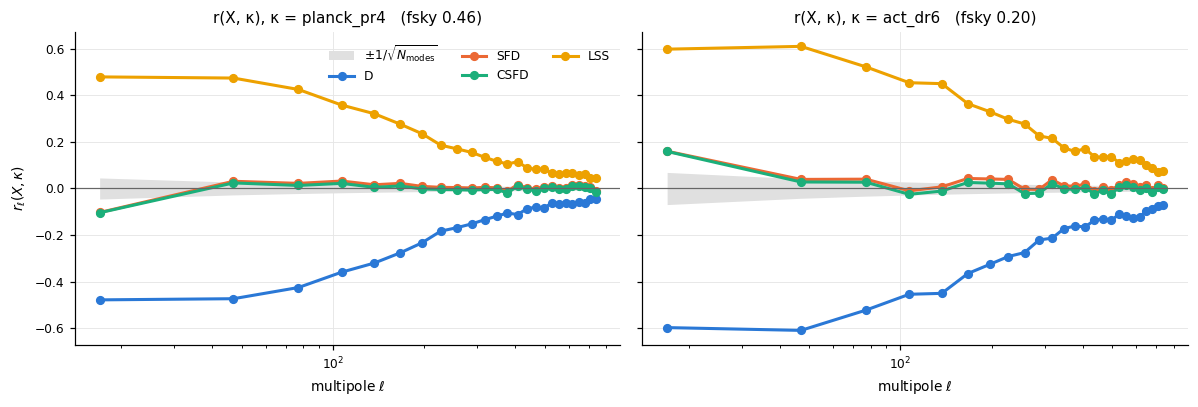

In [7]:
t = read_tables(os.path.join(FIG, "dust_map_check.txt"))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, lens in zip(axes, ("planck_pr4", "act_dr6")):
    key = next(k for k in t if k[1] == lens)
    d = t[key]
    noise_band(ax, d["bins"], fsky_of(d["meta"]))
    for i, x in enumerate(("D", "SFD", "CSFD", "LSS")):
        ax.plot(ell_centres(d["bins"]), d["rows"][f"r({x},k)"], marker="o", color=PAL[i], label=x)
    ax.set_title(f"r(X, κ), κ = {lens}   (fsky {fsky_of(d['meta']):.2f})")
    finish(ax, r"$r_\ell(X,\kappa)$" if lens == "planck_pr4" else None)
axes[0].legend(ncol=3)
plt.tight_layout(); plt.show()

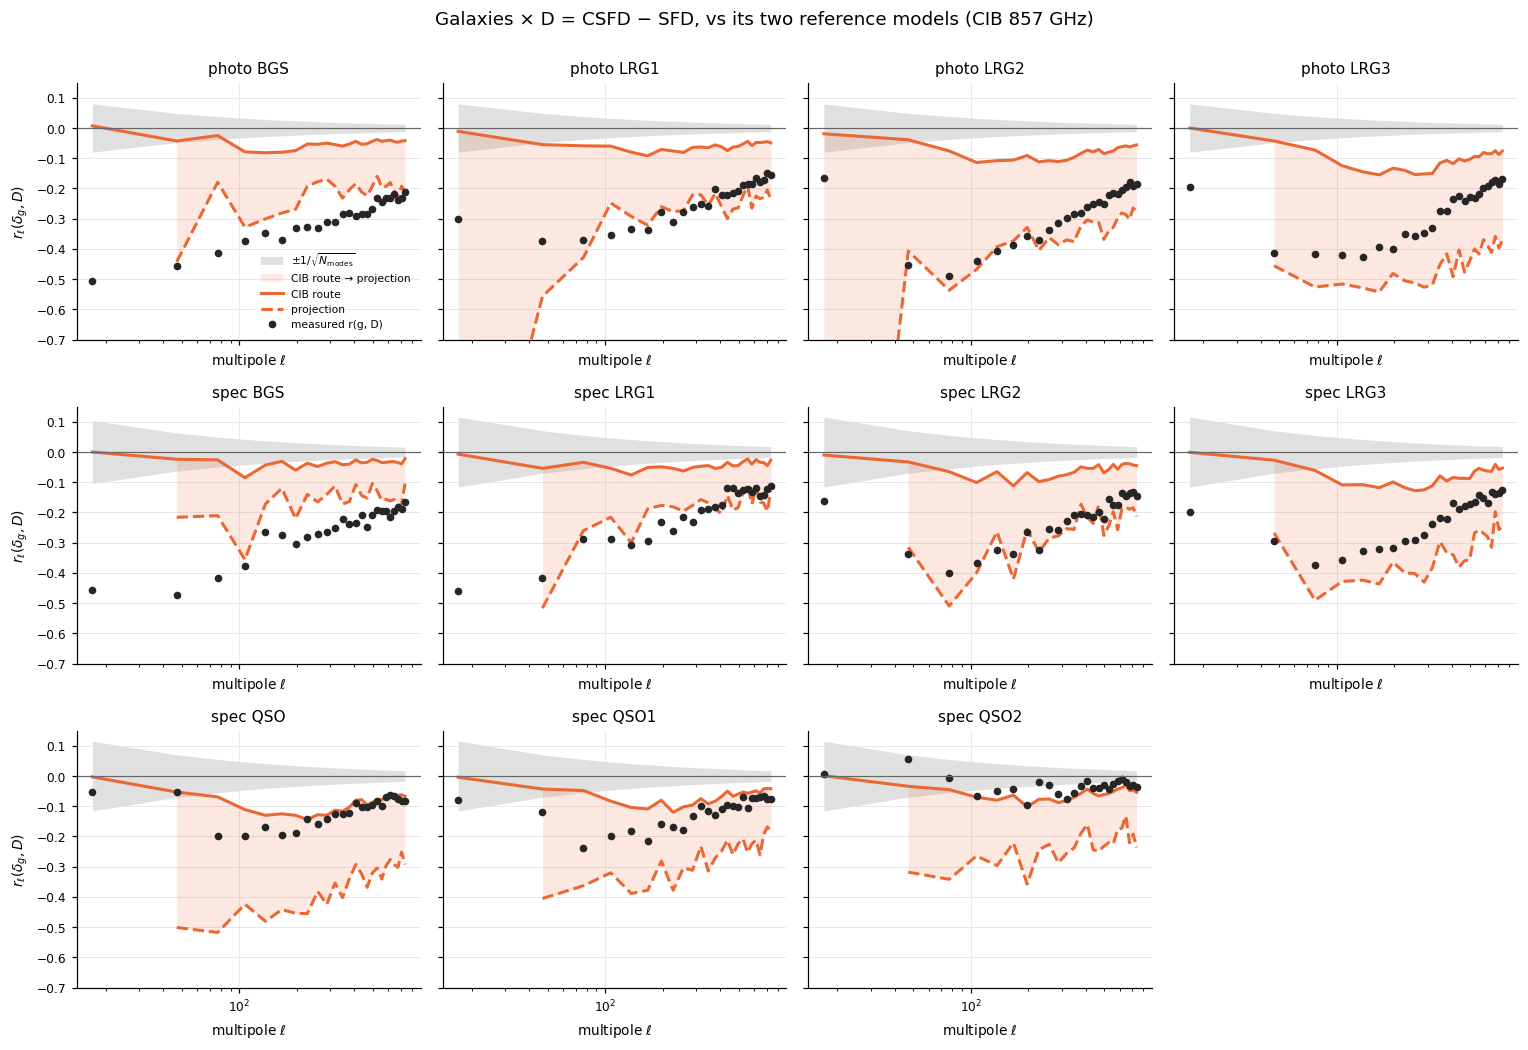

**ℓ ≥ 92, CIB 857 GHz.** position = (measured − route)/(projection − route): 0 at the CIB route, 1 at the projection.

| sample | r(g,D) measured | CIB route | projection | position |
|---|---|---|---|---|
| photo BGS | -0.283 | -0.053 | -0.215 | 1.42 |
| photo LRG1 | -0.232 | -0.062 | -0.250 | 0.91 |
| photo LRG2 | -0.277 | -0.085 | -0.339 | 0.76 |
| photo LRG3 | -0.275 | -0.113 | -0.451 | 0.48 |
| spec BGS | -0.235 | -0.038 | -0.159 | 1.63 |
| spec LRG1 | -0.180 | -0.045 | -0.176 | 1.03 |
| spec LRG2 | -0.219 | -0.063 | -0.249 | 0.84 |
| spec LRG3 | -0.215 | -0.086 | -0.338 | 0.51 |
| spec QSO | -0.117 | -0.096 | -0.355 | 0.08 |
| spec QSO1 | -0.118 | -0.072 | -0.265 | 0.24 |
| spec QSO2 | -0.040 | -0.062 | -0.229 | -0.13 |

In [8]:
fig, axes = plt.subplots(3, 4, figsize=(14, 9.5), sharex=True, sharey=True)
rows_md = []
for ax, (s, T) in zip(axes.flat, TRACERS):
    bins, rows, fsky = euclid_rows(s, T)
    lc = ell_centres(bins)
    meas, route, rgc = rows["r(g_raw, D) measured"], rows["r(g_raw, D) via CIB"], rows["r(g_raw, CIB)"]
    # r(g,c)/r(D,c), with r(D,c) = route / r(g,c); undefined where the route is ~0 (lowest bin)
    proj = np.where(np.abs(route) > 0.01, rgc ** 2 / np.where(route == 0, 1, route), np.nan)
    noise_band(ax, bins, fsky)
    ax.fill_between(lc, route, proj, color=PAL[1], alpha=0.15, lw=0, label="CIB route → projection")
    ax.plot(lc, route, color=PAL[1], label="CIB route")
    ax.plot(lc, proj, "--", color=PAL[1], label="projection")
    ax.plot(lc, meas, "o", ms=4, color="0.15", label="measured r(g, D)")
    ax.set_title(f"{s} {T}"); ax.set_ylim(-0.7, 0.15); finish(ax)
    hi = bins[:, 0] >= 92
    pm = np.nanmean(proj[hi])
    rows_md.append(f"| {s} {T} | {meas[hi].mean():+.3f} | {route[hi].mean():+.3f} | {pm:+.3f} | "
                   f"{(meas[hi].mean() - route[hi].mean()) / (pm - route[hi].mean()):.2f} |")
axes.flat[-1].axis("off"); axes[0, 0].legend(fontsize=7)
for ax in axes[:, 0]:
    ax.set_ylabel(r"$r_\ell(\delta_g, D)$")
plt.suptitle("Galaxies × D = CSFD − SFD, vs its two reference models (CIB 857 GHz)", y=1.0)
plt.tight_layout(); plt.show()
display(Markdown("**ℓ ≥ 92, CIB 857 GHz.** position = (measured − route)/(projection − route): 0 at the CIB route, 1 at the projection.\n\n"
                 "| sample | r(g,D) measured | CIB route | projection | position |\n|---|---|---|---|---|\n" + "\n".join(rows_md)))

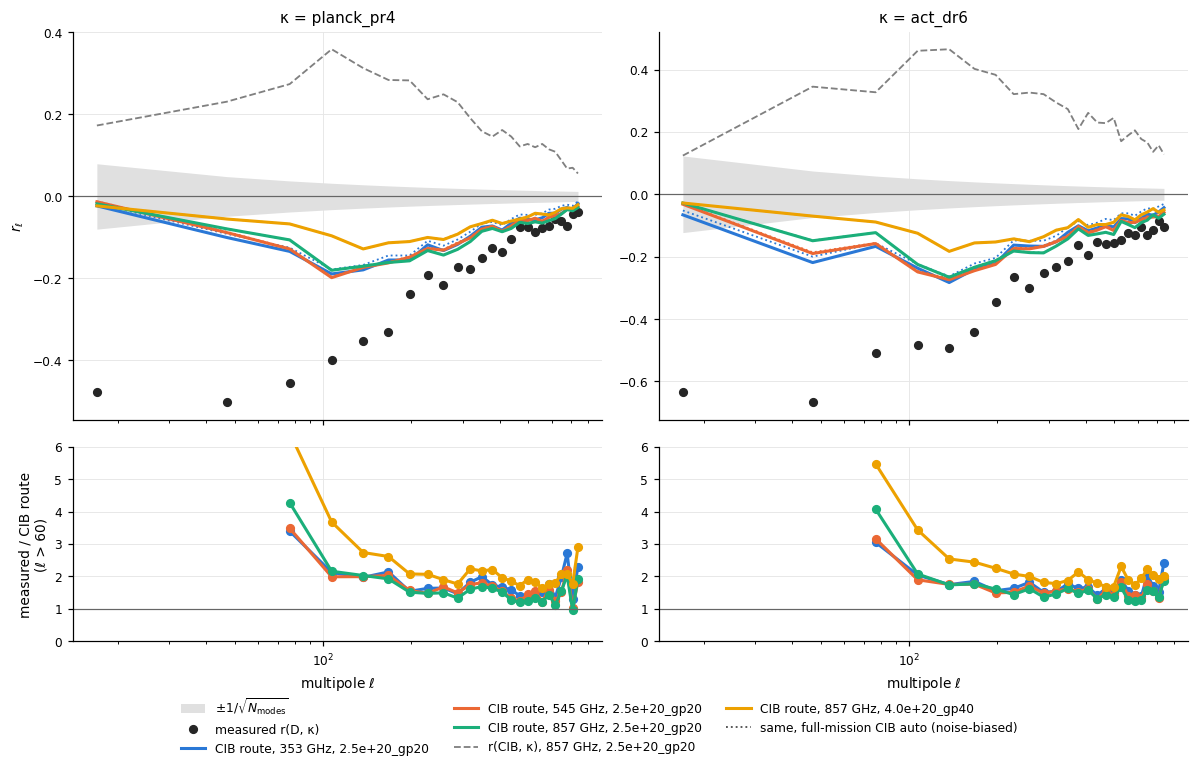

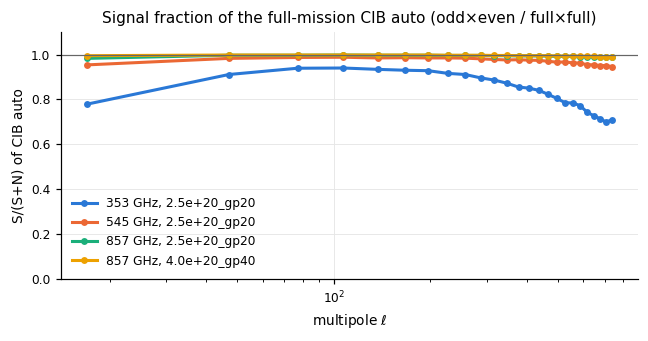

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for col, lens in enumerate(("planck_pr4", "act_dr6")):
    ax, axr = axes[0, col], axes[1, col]
    for i, m in enumerate(maps):
        d = cib[(m, f"{lens} x CIB {m}")]
        lc = ell_centres(d["bins"])
        meas, pred = d["rows"]["r(D, kappa) measured"], d["rows"]["r(D,CIB) r(CIB,kappa)"]
        if i == 0:
            noise_band(ax, d["bins"], fsky_of(d["meta"]))
            ax.plot(lc, meas, "o", color="0.15", label="measured r(D, κ)")
        ax.plot(lc, pred, color=PAL[i], label=f"CIB route, {m}")
        if "r(D,CIB) r(CIB,kappa) fullmission" in d["rows"]:
            ax.plot(lc, d["rows"]["r(D,CIB) r(CIB,kappa) fullmission"], ":", lw=1.2, color=PAL[i])
        axr.plot(lc[lc > 60], (meas / pred)[lc > 60], marker="o", color=PAL[i])
        if m == m857:
            ax.plot(lc, d["rows"]["r(CIB, kappa)"], "--", lw=1.2, color="0.5", label=f"r(CIB, κ), {m}")
    ax.set_title(f"κ = {lens}")
    finish(ax, r"$r_\ell$" if col == 0 else None, xlabel="")
    axr.axhline(1, color="0.4", lw=0.8); axr.set_xscale("log"); axr.set_xlabel(r"multipole $\ell$")
    axr.set_ylim(0, 6)
    if col == 0:
        axr.set_ylabel("measured / CIB route\n(ℓ > 60)")
h, l = axes[0, 0].get_legend_handles_labels()
h.append(plt.Line2D([], [], ls=":", lw=1.2, color="0.3")); l.append("same, full-mission CIB auto (noise-biased)")
fig.legend(h, l, loc="lower center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.08))
plt.tight_layout(); plt.show()

# how much of the full-mission CIB auto is signal: S/(S+N) = C^{odd x even} / C^{full x full}
fig, ax = plt.subplots(figsize=(6, 3.2))
for i, m in enumerate(maps):
    d = cib[(m, f"planck_pr4 x CIB {m}")]
    if "CIB auto S/(S+N)" in d["rows"]:
        ax.plot(ell_centres(d["bins"]), d["rows"]["CIB auto S/(S+N)"], marker="o", ms=3.5, color=PAL[i], label=m)
ax.axhline(1, color="0.4", lw=0.8); ax.set_ylim(0, 1.1); ax.set_xscale("log")
ax.set_xlabel(r"multipole $\ell$"); ax.set_ylabel("S/(S+N) of CIB auto")
ax.set_title("Signal fraction of the full-mission CIB auto (odd×even / full×full)")
ax.legend(); plt.tight_layout(); plt.show()

**Result.**
* D correlates with κ at r ≈ −0.5 (ℓ < 100) to −0.15 (ℓ ~ 400), and with the BGS/LRG samples at r ≈ −0.2 to −0.3. It is the galaxy-traced CIB, so both are expected.
* **Galaxies:** the position on the CIB route → projection scale (table) falls steadily with redshift: BGS 1.4–1.6 (beyond the projection: BGS traces the low-z density structure in D directly, not only through the CIB), LRG1 0.9–1.0, LRG2 0.8, LRG3 0.5, QSO/QSO1 0.1–0.2, QSO2 ≈ 0 (the CIB route). That ordering is what you expect if Chiang's reconstruction is dominated by low-z galaxies: low-z samples see only the galaxy-traced CIB, high-z ones the whole CIB.
* **κ:** measured r(D, κ) is 1.5–3× the CIB route at ℓ ≥ 92, between the two models, since κ integrates CIB from all redshifts.
* The noise-free (odd × even) CIB auto changes the prediction by < 1% at 857 GHz (dotted vs solid, and the S/(S+N) panel). These numbers are not CIB-map noise.
* **Why it matters:** a fit containing both SFD and CSFD can form D. On data it then removes κ-correlated signal (B1). Fitting either map alone cannot.

# Part B. For DESI: our imaging weights do not remove CMB-lensing signal

## B1. Real data: does the dust-map choice change Cgκ?
*Scripts:* `regress_photo_data.py`, `regress_spec_data.py` (real catalogs, same fit as the mocks), `compare_data_variants.py` → `figures/data_variants/<sample>_<T>.npz`.

**What is plotted:** for each variant, (C_ℓ^gκ(variant) − C_ℓ^gκ(baseline)) / σ_Knox(C_ℓ^gκ), for ACT DR6 and Planck PR4. Each variant changes only the imaging weight; all else is fixed (footprint, mask, analysis weights). σ_Knox is the per-bin Gaussian error on C^gκ, so |shift/σ| ≪ 1 means the choice is irrelevant at the per-bin level.

The variants (`config.yaml`):
* **photo** (baseline CSFD+HI):
  * `SFDHI` = SFD+HI
  * `CSFDONLY` = CSFD alone
  * `SPECLIKE` = the spec-BGS-like 4-map list
  * `CSFDSFDHI` = CSFD+SFD+HI, a data-only diagnostic that spans D
* **spec** (baseline = DESI default):
  * `CSFD` = EBV_DIFF re-referenced to CSFD
  * `CSFDHI` = CSFD+HI in place of EBV_DIFF
  * `NOHI` = no HI
  * `ALLEBV` = BGS + EBV_DIFF, the old 5-map list
  * `DESI` = the official catalog weight, a check: it should sit at 0

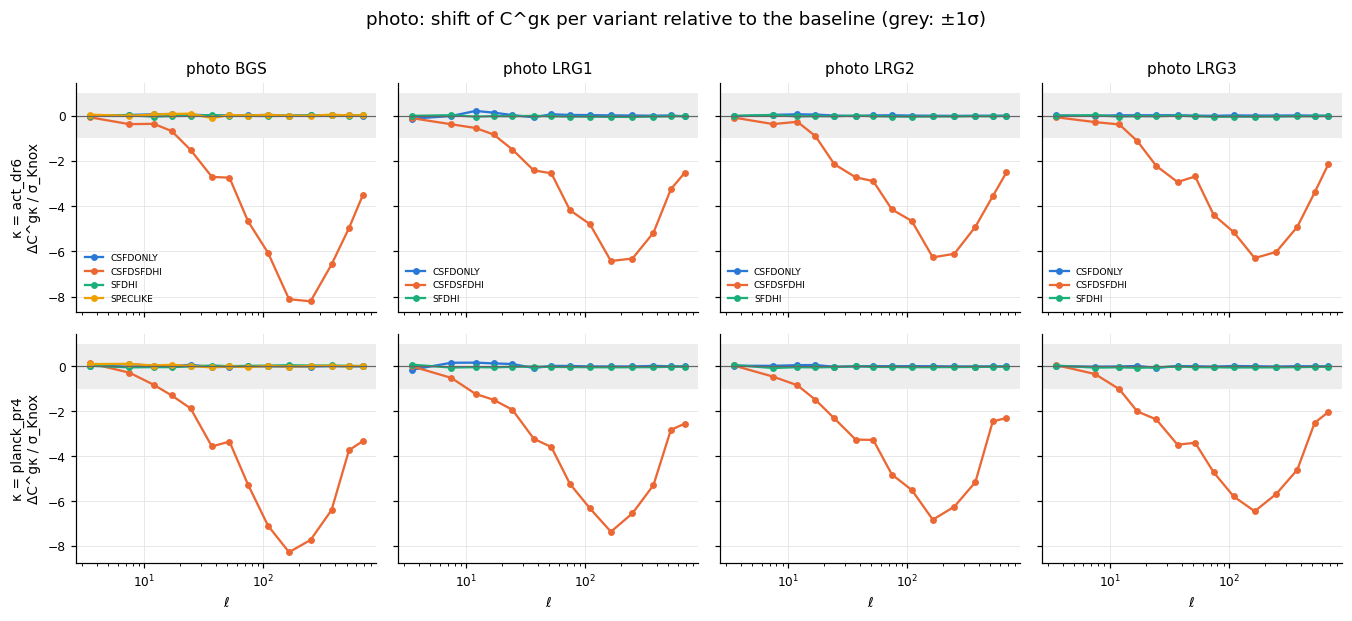

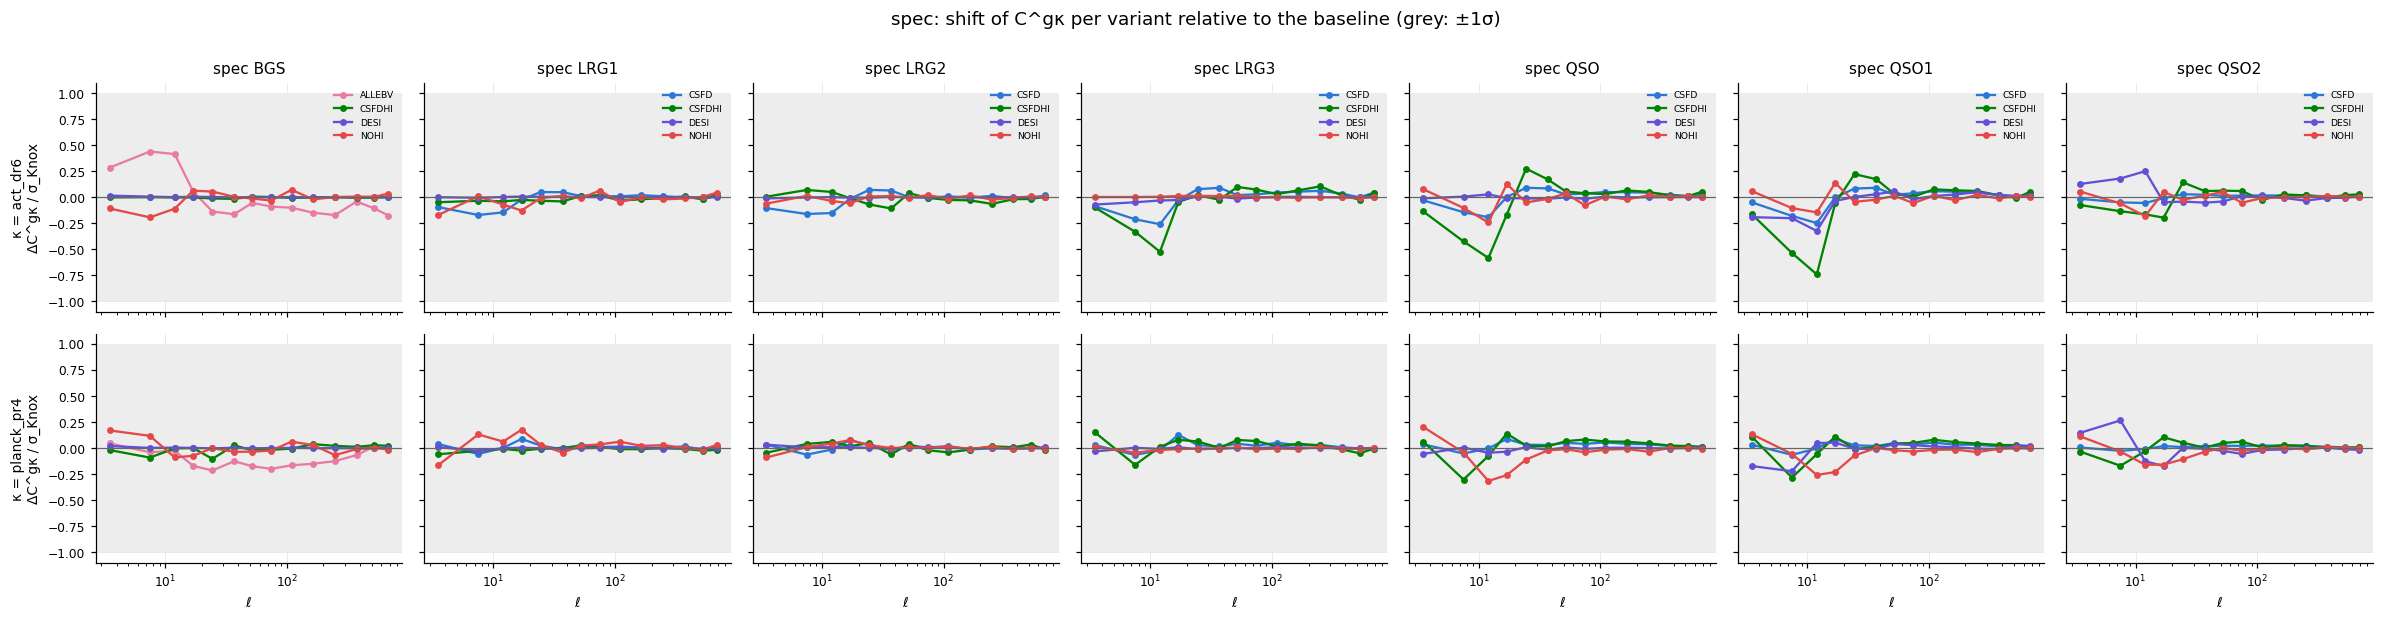

In [10]:
def data_npz(s, T):
    p = os.path.join(FIG, "data_variants", f"{s}_{T}.npz")
    return np.load(p) if os.path.exists(p) else None

def variants_of(z):
    return [k[len("cgg_"):] for k in z if k.startswith("cgg_") and k not in ("cgg_UNWEIGHTED", "cgg_WEIGHT_IMLIN")]

VCOL = {}
for s, trs in (("photo", ("BGS", "LRG1", "LRG2", "LRG3")), ("spec", ("BGS", "LRG1", "LRG2", "LRG3", "QSO", "QSO1", "QSO2"))):
    fig, axes = plt.subplots(2, len(trs), figsize=(3.1 * len(trs), 5.6), sharex=True, sharey="row")
    for j, T in enumerate(trs):
        z = data_npz(s, T)
        if z is None:
            continue
        E = z["ell_edges"]; lc = 0.5 * (E[:-1] + E[1:] - 1)
        for r, L in enumerate(("act_dr6", "planck_pr4")):
            ax = axes[r, j]
            ax.axhspan(-1, 1, color="0.93", lw=0)
            for v in variants_of(z):
                VCOL.setdefault(v, PAL[len(VCOL) % len(PAL)])
                d = (z[f"cgk_{L}_{v}"] - z[f"cgk_{L}_WEIGHT_IMLIN"]) / z[f"sigma_{L}"]
                ax.plot(lc, d, marker="o", ms=3.5, lw=1.5, color=VCOL[v], label=v.replace("WEIGHT_IMLIN_", ""))
            ax.axhline(0, color="0.4", lw=0.8); ax.set_xscale("log")
            if r == 0: ax.set_title(f"{s} {T}")
            if j == 0: ax.set_ylabel(f"κ = {L}\nΔC^gκ / σ_Knox")
            if r == 1: ax.set_xlabel(r"$\ell$")
        axes[0, j].legend(fontsize=6)
    plt.suptitle(f"{s}: shift of C^gκ per variant relative to the baseline (grey: ±1σ)", y=1.0)
    plt.tight_layout(); plt.show()

In [11]:
rows = []
for s, trs in (("photo", ("BGS", "LRG1", "LRG2", "LRG3")), ("spec", ("BGS", "LRG1", "LRG2", "LRG3", "QSO", "QSO1", "QSO2"))):
    for T in trs:
        z = data_npz(s, T)
        if z is None:
            continue
        E = z["ell_edges"]; hi = E[:-1] >= 30
        for v in variants_of(z):
            cells = []
            for L in ("act_dr6", "planck_pr4"):
                ratio = z[f"cgk_{L}_{v}"][hi].sum() / z[f"cgk_{L}_WEIGHT_IMLIN"][hi].sum()
                mx = np.abs((z[f"cgk_{L}_{v}"] - z[f"cgk_{L}_WEIGHT_IMLIN"]) / z[f"sigma_{L}"])[hi].max()
                cells.append(f"{ratio:.3f} | {mx:.2f}")
            gg = z[f"cgg_{v}"][E[:-1] >= 10] / z["cgg_WEIGHT_IMLIN"][E[:-1] >= 10]
            rows.append(f"| {s} {T} | {v.replace('WEIGHT_IMLIN_', '')} | " + " | ".join(cells) + f" | {np.abs(gg - 1).max():.3f} |")
display(Markdown("**Summary, ℓ ≥ 30** (ratio = Σ C^gκ(variant) / Σ C^gκ(baseline); max |Δ/σ| per bin; Cgg: max |ratio − 1| at ℓ ≥ 10)\n\n"
                 "| sample | variant | ACT ratio | ACT max\\|Δ/σ\\| | Planck ratio | Planck max\\|Δ/σ\\| | Cgg max\\|Δ\\| |\n|---|---|---|---|---|---|---|\n" + "\n".join(rows)))

**Summary, ℓ ≥ 30** (ratio = Σ C^gκ(variant) / Σ C^gκ(baseline); max |Δ/σ| per bin; Cgg: max |ratio − 1| at ℓ ≥ 10)

| sample | variant | ACT ratio | ACT max\|Δ/σ\| | Planck ratio | Planck max\|Δ/σ\| | Cgg max\|Δ\| |
|---|---|---|---|---|---|---|
| photo BGS | CSFDONLY | 1.002 | 0.04 | 0.997 | 0.03 | 0.013 |
| photo BGS | CSFDSFDHI | 0.299 | 8.21 | 0.268 | 8.28 | 0.192 |
| photo BGS | SFDHI | 1.002 | 0.02 | 1.005 | 0.05 | 0.005 |
| photo BGS | SPECLIKE | 0.994 | 0.11 | 0.997 | 0.05 | 0.030 |
| photo LRG1 | CSFDONLY | 0.999 | 0.07 | 0.997 | 0.07 | 0.014 |
| photo LRG1 | CSFDSFDHI | 0.395 | 6.43 | 0.317 | 7.37 | 0.165 |
| photo LRG1 | SFDHI | 0.996 | 0.05 | 0.997 | 0.04 | 0.006 |
| photo LRG2 | CSFDONLY | 1.000 | 0.02 | 1.001 | 0.01 | 0.014 |
| photo LRG2 | CSFDSFDHI | 0.435 | 6.27 | 0.465 | 6.83 | 0.194 |
| photo LRG2 | SFDHI | 0.998 | 0.04 | 0.998 | 0.03 | 0.002 |
| photo LRG3 | CSFDONLY | 1.001 | 0.02 | 1.001 | 0.02 | 0.014 |
| photo LRG3 | CSFDSFDHI | 0.486 | 6.30 | 0.539 | 6.45 | 0.219 |
| photo LRG3 | SFDHI | 0.997 | 0.05 | 0.997 | 0.05 | 0.009 |
| spec BGS | ALLEBV | 0.972 | 0.18 | 0.969 | 0.20 | 0.062 |
| spec BGS | CSFDHI | 0.999 | 0.02 | 1.001 | 0.04 | 0.036 |
| spec BGS | DESI | 1.000 | 0.00 | 1.000 | 0.00 | 0.001 |
| spec BGS | NOHI | 1.000 | 0.07 | 0.995 | 0.07 | 0.011 |
| spec LRG1 | CSFD | 1.008 | 0.05 | 1.001 | 0.03 | 0.009 |
| spec LRG1 | CSFDHI | 0.995 | 0.04 | 1.001 | 0.02 | 0.016 |
| spec LRG1 | DESI | 1.000 | 0.00 | 1.000 | 0.01 | 0.003 |
| spec LRG1 | NOHI | 1.002 | 0.06 | 1.000 | 0.06 | 0.031 |
| spec LRG2 | CSFD | 1.006 | 0.06 | 1.001 | 0.02 | 0.014 |
| spec LRG2 | CSFDHI | 0.991 | 0.11 | 0.996 | 0.06 | 0.042 |
| spec LRG2 | DESI | 1.000 | 0.00 | 1.000 | 0.01 | 0.004 |
| spec LRG2 | NOHI | 1.001 | 0.02 | 1.001 | 0.01 | 0.017 |
| spec LRG3 | CSFD | 1.012 | 0.09 | 1.005 | 0.05 | 0.020 |
| spec LRG3 | CSFDHI | 1.009 | 0.10 | 1.006 | 0.08 | 0.085 |
| spec LRG3 | DESI | 0.999 | 0.01 | 1.000 | 0.01 | 0.007 |
| spec LRG3 | NOHI | 1.002 | 0.01 | 1.000 | 0.01 | 0.007 |
| spec QSO | CSFD | 1.010 | 0.08 | 1.007 | 0.05 | 0.055 |
| spec QSO | CSFDHI | 1.018 | 0.17 | 1.009 | 0.08 | 0.072 |
| spec QSO | DESI | 0.998 | 0.02 | 0.999 | 0.02 | 0.038 |
| spec QSO | NOHI | 0.998 | 0.08 | 0.996 | 0.04 | 0.404 |
| spec QSO1 | CSFD | 1.013 | 0.09 | 1.007 | 0.05 | 0.008 |
| spec QSO1 | CSFDHI | 1.019 | 0.17 | 1.008 | 0.08 | 0.054 |
| spec QSO1 | DESI | 1.006 | 0.06 | 1.003 | 0.04 | 0.280 |
| spec QSO1 | NOHI | 0.997 | 0.06 | 0.997 | 0.04 | 0.345 |
| spec QSO2 | CSFD | 1.006 | 0.02 | 1.006 | 0.02 | 0.021 |
| spec QSO2 | CSFDHI | 1.016 | 0.06 | 1.008 | 0.06 | 0.066 |
| spec QSO2 | DESI | 0.990 | 0.05 | 0.994 | 0.06 | 0.401 |
| spec QSO2 | NOHI | 1.003 | 0.05 | 0.995 | 0.04 | 0.037 |

**Result.**
* **Photo baseline (CSFD+HI) is safe.** SFD+HI and CSFD-only give the same Cgκ within 0.5% (≤ 0.07σ per bin).
* **CSFD+SFD+HI removes 46–73% of Cgκ** (up to 6–8σ per bin) and 5–20% of Cgg. With both maps free, the fit builds ≈ 9 × (CSFD − SFD), the D direction of §1–4, which correlates with both κ and the galaxies. This is the risk the tests were designed to catch, and it is real. Never use this combination.
* **Spec:** re-referencing EBV_DIFF to CSFD, or replacing it with CSFD+HI, *raises* Cgκ by 0.1–1.9%. Adding EBV_DIFF to BGS lowers it by 3%. The same sign everywhere suggests the DESI EBV_DIFF (which contains −(SFD's CIB)) removes ~1% of the κ correlation. That is ≤ 0.2σ per bin, but coherent across bins and tracers. The per-bin Knox σ does not give a combined significance, because the variants share almost all their noise.
* **Validation:** `DESI` (the official catalog weight) sits at 0, as it must. Refit vs official weights: corr 0.994–0.9985 (LRG, QSO, BGS 3-map).

## B2. Mocks: how much clustering does the regression remove? (mode removal)
*Scripts:* `regress_photo_mocks.py`, `regress_spec_mocks.py`, `compare_variants.py` → `figures/variants/<sample>_<lensmap>_<T>.npz`.
The lognormal mocks have **no injected systematics**, so any power the weights remove is real clustering lost to the fit. That is the correction needed for the data.

**What is plotted:** ⟨C_ℓ^gg(baseline weights)⟩ / ⟨C_ℓ^gg(unweighted)⟩ over the mocks (shot-noise subtracted pseudo-C_ℓ), (ratio of means), with the error on the mean. Left: photo samples. Right: spec samples (act_dr6 mocks).

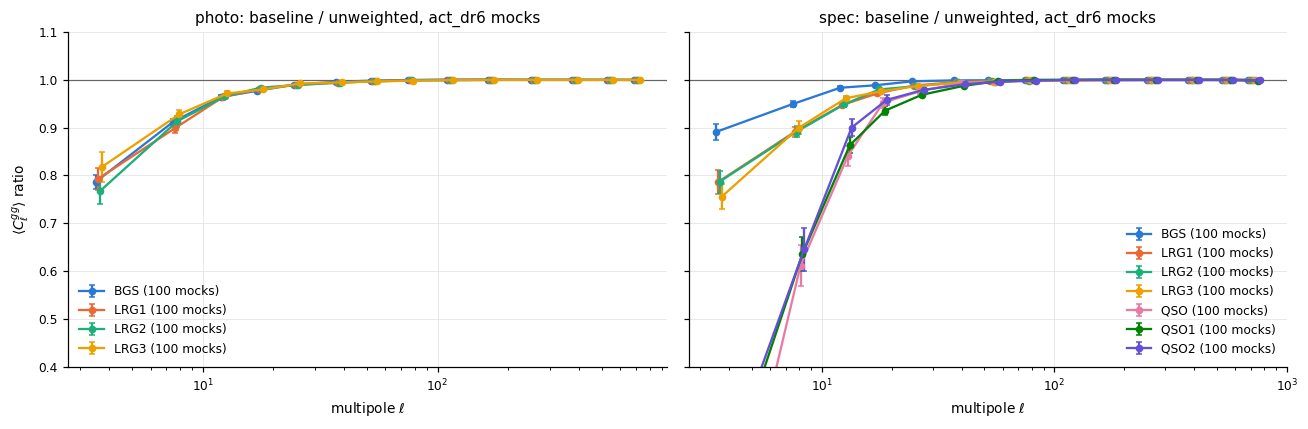

In [12]:
def ratio_of_means(num, den, per_sky=False):
    # <num>/<den> over the mocks; error from the per-mock scatter of num - R*den
    # (error on the mean, or with per_sky=True the scatter for a single sky).
    # Robust where a shot-noise-subtracted C_l is near zero (spec QSO, l < 10).
    R = num.mean(0) / den.mean(0)
    e = (num - R * den).std(0, ddof=1) / den.mean(0)
    return R, e if per_sky else e / np.sqrt(len(num))

def mock_npz(s, T, lens="act_dr6"):
    p = os.path.join(FIG, "variants", f"{s}_{lens}_{T}.npz")
    return np.load(p) if os.path.exists(p) else None

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, s, trs in ((axes[0], "photo", ("BGS", "LRG1", "LRG2", "LRG3")),
                   (axes[1], "spec", ("BGS", "LRG1", "LRG2", "LRG3", "QSO", "QSO1", "QSO2"))):
    for i, T in enumerate(trs):
        z = mock_npz(s, T)
        if z is None:
            continue
        E = z["ell_edges"]; lc = 0.5 * (E[:-1] + E[1:] - 1)
        m, e = ratio_of_means(z["cl_WEIGHT_IMLIN"], z["cl_UNWEIGHTED"])
        ax.errorbar(lc * (1 + 0.02 * i), m, e, marker="o", ms=4, lw=1.5, capsize=2, color=PAL[i], label=f"{T} ({len(z['sims'])} mocks)")
    ax.axhline(1, color="0.4", lw=0.8); ax.set_xscale("log"); ax.set_xlabel(r"multipole $\ell$")
    ax.set_title(f"{s}: baseline / unweighted, act_dr6 mocks"); ax.legend()
axes[0].set_ylabel(r"$\langle C_\ell^{gg}\rangle$ ratio"); axes[0].set_ylim(0.4, 1.1)
plt.tight_layout(); plt.show()

**Result** (act_dr6 mocks; planck_pr4 agrees). ℓ = 2–5 | 6–9 | 10–14 | 15–19:
* **Photo:** BGS 0.79–0.80 | 0.91 | 0.96; LRG1–3 0.80–0.87 | 0.90–0.93 | 0.96–0.98; < 1% at ℓ ≳ 30.
* **Spec BGS** (DESI 3-map default): 0.89 | 0.95 | 0.98 | 0.99, ≤ 0.3% at ℓ ≥ 20. The old 5-map list (`ALLEBV`) removes more (ALLEBV/baseline 0.93 at ℓ = 2–5).
* **Spec LRG1–3:** 0.73–0.80 | 0.88–0.90 | 0.95–0.96 | 0.97–0.98, similar to photo.
* **Spec QSO/QSO1/QSO2:** undefined at ℓ = 2–5 (the mean mock QSO C^gg is ≈ 0 there after shot-noise subtraction; PNG_DR2 finds the same in these mocks) | 0.58–0.65 | 0.84–0.90 | 0.92–0.96, ≤ 3% at ℓ ≥ 20.

This is the mode-removal correction to apply to the data Cℓ. Gerrit measures it on the analysis grid from the sidecars in `outputs/`.

*Corrected 2026-10-26.* `compare_variants.py` used to give spec mock objects unit weight while the spec randoms are weighted WEIGHT·FKP/SYS/ZFAIL, which added spurious large-scale power and pushed every spec ratio towards 1 (the old "spec is much milder, LRG 0.97–1.00, QSO ≈ 1"). Objects now carry the randoms' weight and z cut. Weights, sidecars, photo and all real-data results are unaffected.

**Dust-variant choice on mocks** (variant / baseline): SFD↔CSFD ≤ 0.3% everywhere; spec CSFD+HI 1.04–1.11 at ℓ = 2–5 (LRG) and up to 1.15 at ℓ = 6–9 (QSO), ≤ 1% at ℓ ≥ 30; no-HI ≤ 3%. See `README.md` → Full 100-mock results.

## B3. Real data: does the map choice change Cgg?
*Scripts:* `compare_data_variants.py` (data) and `compare_variants.py` (the same ratios on 100 act_dr6 mocks).

Unlike Cgκ, Cgg is directly sensitive to imaging contamination: contamination *adds* power, so each weight choice leaves its own residual at low ℓ. On data alone, a shift between two weights cannot tell over-correction from leftover contamination, so the same ratio on the mocks (no contamination) gives the null:
* **is the shift real?** Compare the data ratio with its spread over the mocks (single-sky 1σ). Mocks only show the shift that comes from fitting noise.
* **does it matter?** ΔC = C^gg_data(variant) − C^gg_data(baseline), in units of the single-sky statistical error σ(C^gg) from the mocks.

**What is plotted:** points = data C^gg(variant)/C^gg(baseline); band of the same colour = mean ± 1σ of the same ratio over the mocks (single sky, ratio of means). Variants without a band (`CSFDSFDHI`, `DESI`) exist only on data. First figure: the weights themselves (baseline/unweighted), data vs mocks.

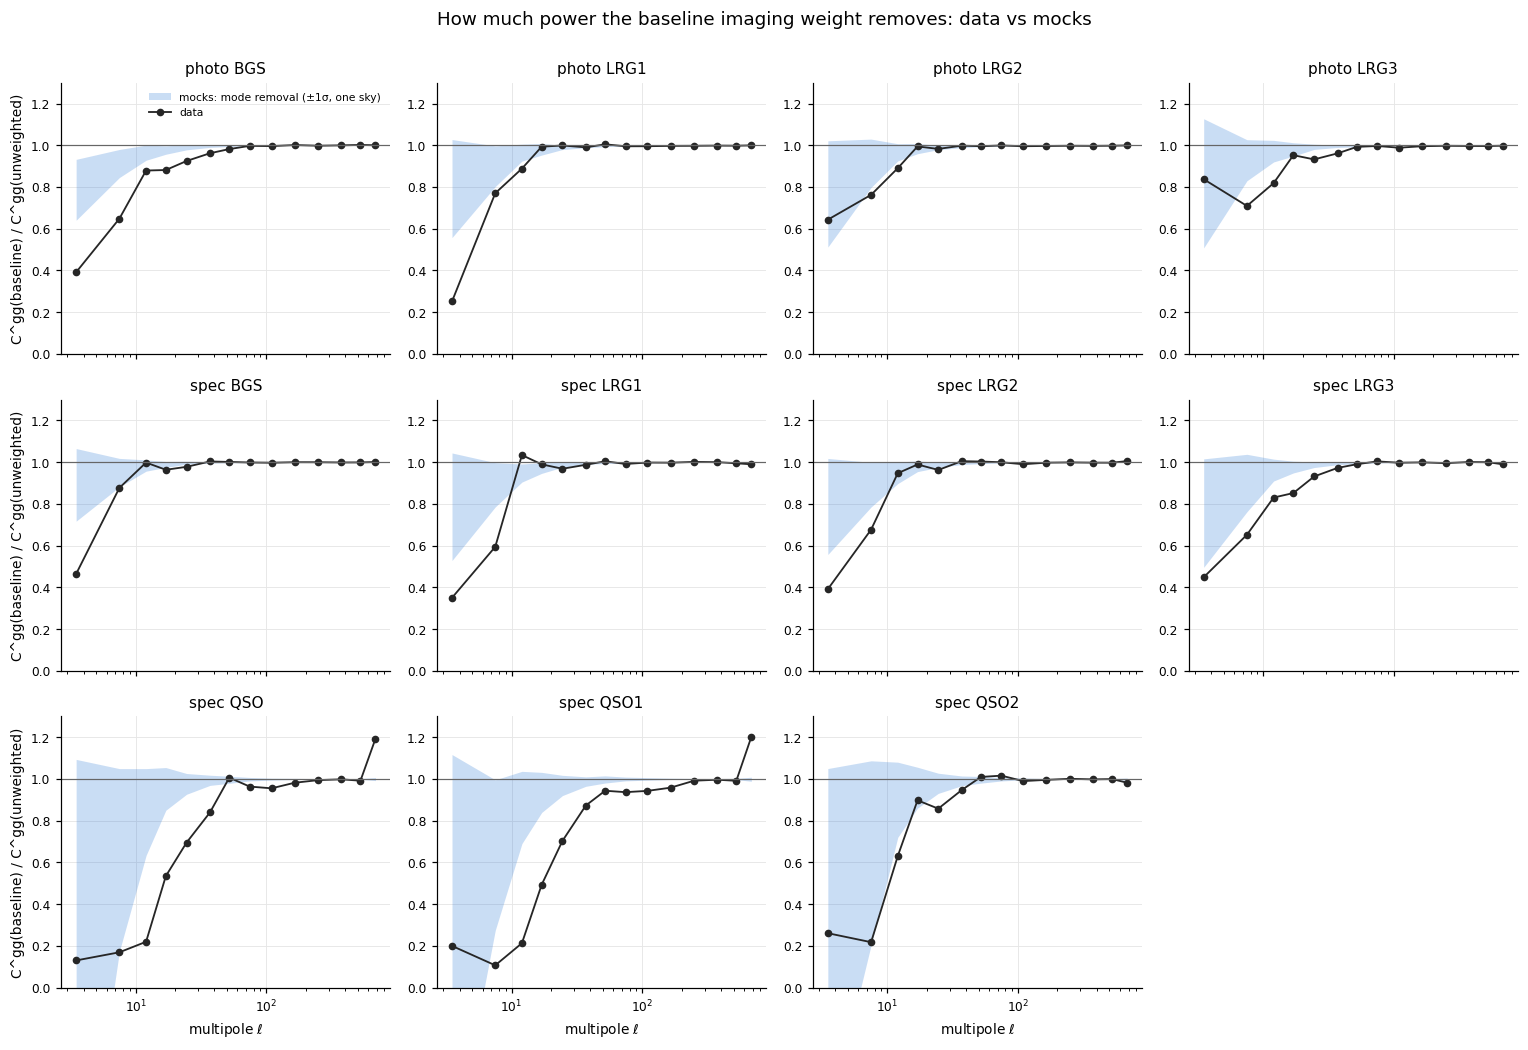

In [13]:
TR_ALL = [("photo", T) for T in ("BGS", "LRG1", "LRG2", "LRG3")] + [("spec", T) for T in ("BGS", "LRG1", "LRG2", "LRG3", "QSO", "QSO1", "QSO2")]

def panel_grid():
    fig, axes = plt.subplots(3, 4, figsize=(14, 9.5), sharex=True)
    axes.flat[-1].axis("off")
    return fig, axes

# 1. how much the baseline weight removes: data vs mocks (mocks = mode removal only)
fig, axes = panel_grid()
for ax, (s, T) in zip(axes.flat, TR_ALL):
    d, z = data_npz(s, T), mock_npz(s, T)
    E = d["ell_edges"]; lc = 0.5 * (E[:-1] + E[1:] - 1)
    m, e = ratio_of_means(z["cl_WEIGHT_IMLIN"], z["cl_UNWEIGHTED"], per_sky=True)
    ax.fill_between(lc, m - e, m + e, color=PAL[0], alpha=0.25, lw=0, label="mocks: mode removal (±1σ, one sky)")
    ax.plot(lc, d["cgg_WEIGHT_IMLIN"] / d["cgg_UNWEIGHTED"], "o-", ms=4, lw=1.2, color="0.15", label="data")
    ax.axhline(1, color="0.4", lw=0.8); ax.set_xscale("log"); ax.set_ylim(0, 1.3); ax.set_title(f"{s} {T}")
for ax in axes[:, 0]:
    ax.set_ylabel("C^gg(baseline) / C^gg(unweighted)")
for ax in axes[-1]:
    ax.set_xlabel(r"multipole $\ell$")
axes[0, 0].legend(fontsize=7)
plt.suptitle("How much power the baseline imaging weight removes: data vs mocks", y=1.0)
plt.tight_layout(); plt.show()

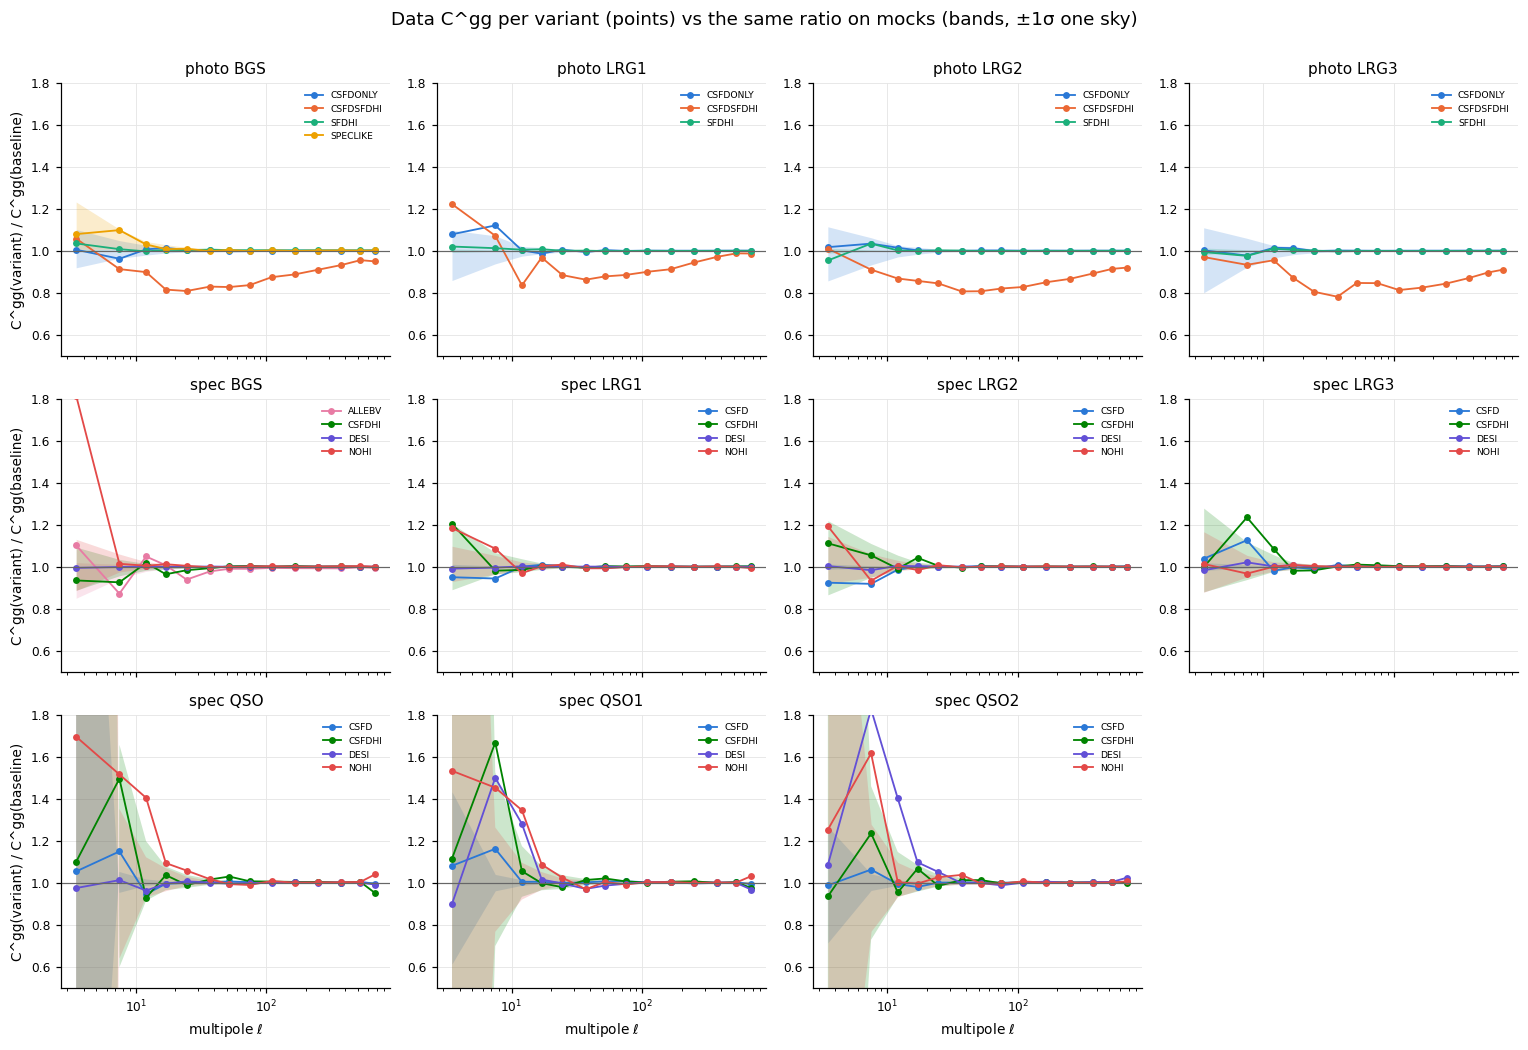

**ℓ = 2–9 and 10–29.** data = ΣC(variant)/ΣC(baseline) on data; mocks = the same ratio over the act_dr6 mocks, mean ± single-sky σ; z = (data − mock mean)/σ (*is it real?*); ΔC/σ_C = data shift in units of the single-sky error on C^gg (*does it matter?*).

| sample | variant | ℓ 2–9 data | mocks | z | ΔC/σ_C | ℓ 10–29 data | mocks | z | ΔC/σ_C |
|---|---|---|---|---|---|---|---|---|---|
| photo BGS | CSFDONLY | 0.993 | 1.007 ± 0.044 | -0.3 | -0.12 | 1.007 | 1.001 ± 0.010 | +0.6 | +0.10 |
| photo BGS | CSFDSFDHI | 1.020 | – | – | +0.34 | 0.850 | – | – | -2.00 |
| photo BGS | SFDHI | 1.027 | 1.000 ± 0.002 | +11.5 | +0.47 | 1.000 | 1.000 ± 0.001 | +0.4 | +0.00 |
| photo BGS | SPECLIKE | 1.084 | 1.079 ± 0.057 | +0.1 | +1.44 | 1.018 | 1.015 ± 0.010 | +0.2 | +0.24 |
| photo LRG1 | CSFDONLY | 1.101 | 0.994 ± 0.061 | +1.7 | +0.78 | 0.997 | 0.999 ± 0.009 | -0.2 | -0.03 |
| photo LRG1 | CSFDSFDHI | 1.140 | – | – | +1.08 | 0.896 | – | – | -1.23 |
| photo LRG1 | SFDHI | 1.015 | 1.000 ± 0.004 | +4.3 | +0.12 | 1.003 | 1.000 ± 0.001 | +6.2 | +0.04 |
| photo LRG2 | CSFDONLY | 1.020 | 0.992 ± 0.069 | +0.4 | +0.41 | 1.006 | 0.999 ± 0.010 | +0.7 | +0.09 |
| photo LRG2 | CSFDSFDHI | 0.988 | – | – | -0.24 | 0.857 | – | – | -2.19 |
| photo LRG2 | SFDHI | 0.970 | 1.000 ± 0.006 | -5.3 | -0.59 | 1.000 | 1.000 ± 0.001 | +0.2 | +0.00 |
| photo LRG3 | CSFDONLY | 0.998 | 0.977 ± 0.065 | +0.3 | -0.19 | 1.008 | 0.998 ± 0.011 | +0.9 | +0.12 |
| photo LRG3 | CSFDSFDHI | 0.964 | – | – | -3.09 | 0.886 | – | – | -1.67 |
| photo LRG3 | SFDHI | 0.991 | 0.998 ± 0.007 | -1.1 | -0.81 | 1.005 | 1.000 ± 0.001 | +5.4 | +0.07 |
| spec BGS | ALLEBV | 0.955 | 0.959 ± 0.046 | -0.1 | -0.34 | 1.008 | 0.995 ± 0.006 | +2.0 | +0.07 |
| spec BGS | CSFDHI | 0.929 | 0.993 ± 0.054 | -1.2 | -0.55 | 0.992 | 1.000 ± 0.008 | -1.0 | -0.07 |
| spec BGS | DESI | 0.997 | – | – | -0.03 | 1.000 | – | – | -0.00 |
| spec BGS | NOHI | 1.306 | 1.013 ± 0.059 | +5.0 | +2.34 | 1.006 | 1.004 ± 0.008 | +0.3 | +0.06 |
| spec LRG1 | CSFD | 0.947 | 1.000 ± 0.005 | -11.0 | -0.37 | 1.004 | 1.000 ± 0.001 | +6.3 | +0.04 |
| spec LRG1 | CSFDHI | 1.110 | 1.028 ± 0.075 | +1.1 | +0.76 | 0.995 | 1.003 ± 0.013 | -0.6 | -0.05 |
| spec LRG1 | DESI | 0.992 | – | – | -0.05 | 0.999 | – | – | -0.01 |
| spec LRG1 | NOHI | 1.143 | 1.010 ± 0.044 | +3.0 | +0.99 | 0.992 | 1.002 ± 0.007 | -1.3 | -0.08 |
| spec LRG2 | CSFD | 0.921 | 0.999 ± 0.006 | -13.4 | -0.69 | 0.995 | 1.000 ± 0.001 | -8.8 | -0.07 |
| spec LRG2 | CSFDHI | 1.083 | 1.034 ± 0.097 | +0.5 | +0.72 | 1.014 | 1.008 ± 0.013 | +0.5 | +0.19 |
| spec LRG2 | DESI | 0.993 | – | – | -0.06 | 1.002 | – | – | +0.03 |
| spec LRG2 | NOHI | 1.064 | 1.015 ± 0.058 | +0.8 | +0.56 | 0.997 | 1.003 ± 0.008 | -0.8 | -0.04 |
| spec LRG3 | CSFD | 1.066 | 1.001 ± 0.009 | +7.2 | +0.93 | 0.988 | 1.000 ± 0.001 | -11.6 | -0.12 |
| spec LRG3 | CSFDHI | 1.073 | 1.048 ± 0.109 | +0.2 | +1.03 | 1.019 | 1.006 ± 0.014 | +0.9 | +0.18 |
| spec LRG3 | DESI | 0.995 | – | – | -0.08 | 1.002 | – | – | +0.02 |
| spec LRG3 | NOHI | 0.998 | 1.010 ± 0.071 | -0.2 | -0.03 | 1.003 | 1.002 ± 0.009 | +0.1 | +0.03 |
| spec QSO | CSFD | 1.083 | 0.984 ± 0.127 | +0.8 | +0.65 | 0.987 | 1.000 ± 0.005 | -2.4 | -0.06 |
| spec QSO | CSFDHI | 1.221 | 1.298 ± 1.029 | -0.1 | +1.75 | 0.994 | 1.023 ± 0.044 | -0.7 | -0.03 |
| spec QSO | DESI | 0.986 | – | – | -0.11 | 0.994 | – | – | -0.03 |
| spec QSO | NOHI | 1.640 | 1.229 ± 0.962 | +0.4 | +5.07 | 1.136 | 1.013 ± 0.033 | +3.7 | +0.66 |
| spec QSO1 | CSFD | 1.095 | 1.003 ± 0.067 | +1.4 | +0.58 | 1.002 | 1.001 ± 0.005 | +0.2 | +0.01 |
| spec QSO1 | CSFDHI | 1.218 | 1.268 ± 0.695 | -0.1 | +1.32 | 1.002 | 1.022 ± 0.044 | -0.4 | +0.01 |
| spec QSO1 | DESI | 1.011 | – | – | +0.07 | 1.066 | – | – | +0.32 |
| spec QSO1 | NOHI | 1.517 | 1.091 ± 0.403 | +1.1 | +3.15 | 1.119 | 1.005 ± 0.029 | +3.9 | +0.58 |
| spec QSO2 | CSFD | 0.997 | 1.000 ± 0.068 | -0.0 | -0.02 | 0.994 | 1.000 ± 0.004 | -1.3 | -0.02 |
| spec QSO2 | CSFDHI | 0.975 | 1.210 ± 0.614 | -0.4 | -0.16 | 0.990 | 1.021 ± 0.042 | -0.7 | -0.03 |
| spec QSO2 | DESI | 1.184 | – | – | +1.14 | 1.170 | – | – | +0.61 |
| spec QSO2 | NOHI | 1.301 | 1.073 ± 0.441 | +0.5 | +1.87 | 1.012 | 1.010 ± 0.029 | +0.1 | +0.04 |

In [14]:
# 2. each variant vs the baseline: data points, mock band
fig, axes = panel_grid()
for ax, (s, T) in zip(axes.flat, TR_ALL):
    d, z = data_npz(s, T), mock_npz(s, T)
    E = d["ell_edges"]; lc = 0.5 * (E[:-1] + E[1:] - 1)
    for v in variants_of(d):
        c = VCOL.setdefault(v, PAL[len(VCOL) % len(PAL)])
        if f"cl_{v}" in z:
            m, e = ratio_of_means(z[f"cl_{v}"], z["cl_WEIGHT_IMLIN"], per_sky=True)
            ax.fill_between(lc, m - e, m + e, color=c, alpha=0.2, lw=0)
        ax.plot(lc, d[f"cgg_{v}"] / d["cgg_WEIGHT_IMLIN"], "o-", ms=3.5, lw=1.2, color=c, label=v.replace("WEIGHT_IMLIN_", ""))
    ax.axhline(1, color="0.4", lw=0.8); ax.set_xscale("log"); ax.set_ylim(0.5, 1.8); ax.set_title(f"{s} {T}")
    ax.legend(fontsize=6)
for ax in axes[:, 0]:
    ax.set_ylabel("C^gg(variant) / C^gg(baseline)")
for ax in axes[-1]:
    ax.set_xlabel(r"multipole $\ell$")
plt.suptitle("Data C^gg per variant (points) vs the same ratio on mocks (bands, ±1σ one sky)", y=1.0)
plt.tight_layout(); plt.show()

# 3. table: l = 2-9 and 10-29 (sums of the band powers)
def band_stats(d, z, v, sel):
    cd = d[f"cgg_{v}"][sel].sum(); cb = d["cgg_WEIGHT_IMLIN"][sel].sum()
    sig = z["cl_WEIGHT_IMLIN"][:, sel].sum(1).std(ddof=1)  # single-sky error on the baseline C^gg
    if f"cl_{v}" in z:
        m, e = ratio_of_means(z[f"cl_{v}"][:, sel].sum(1)[:, None], z["cl_WEIGHT_IMLIN"][:, sel].sum(1)[:, None], per_sky=True)
        mock = f"{m[0]:.3f} ± {e[0]:.3f}"; zsc = f"{(cd / cb - m[0]) / e[0]:+.1f}"
    else:
        mock, zsc = "–", "–"
    return f"{cd / cb:.3f} | {mock} | {zsc} | {(cd - cb) / sig:+.2f}"

rows = []
for s, T in TR_ALL:
    d, z = data_npz(s, T), mock_npz(s, T)
    E = d["ell_edges"]; lo = E[:-1] < 10; mid = (E[:-1] >= 10) & (E[:-1] < 30)
    for v in variants_of(d):
        rows.append(f"| {s} {T} | {v.replace('WEIGHT_IMLIN_', '')} | {band_stats(d, z, v, lo)} | {band_stats(d, z, v, mid)} |")
display(Markdown(
    "**ℓ = 2–9 and 10–29.** data = ΣC(variant)/ΣC(baseline) on data; mocks = the same ratio over the act_dr6 mocks, mean ± single-sky σ; "
    "z = (data − mock mean)/σ (*is it real?*); ΔC/σ_C = data shift in units of the single-sky error on C^gg (*does it matter?*).\n\n"
    "| sample | variant | ℓ 2–9 data | mocks | z | ΔC/σ_C | ℓ 10–29 data | mocks | z | ΔC/σ_C |\n|---|---|---|---|---|---|---|---|---|---|\n" + "\n".join(rows)))

**Result.**
* **The weights remove real contamination** (first figure). At ℓ < 20 the data lose far more power to the baseline weight than the mocks do (e.g. spec QSO 0.17–0.22 on data vs 0.61–0.84 on mocks at ℓ = 6–14; photo LRG1 0.25 vs 0.8 at ℓ = 2–5). The mocks show only mode removal; the rest is imaging contamination being corrected.
* **The dust choice does not matter for Cgg.** SFD↔CSFD (photo `SFDHI`, spec `CSFD`) shifts lie outside the mock spread (z up to ±13), because on mocks the two fits are nearly identical and the spread is tiny: the shift is a real response to the sky. But it is small: ≤ 0.9 σ_C at ℓ = 2–9 and ≤ 0.12 σ_C at ℓ = 10–29. CSFD-only and the spec CSFD+HI block sit inside the mock spread.
* **HI matters at low ℓ.** Without HI, data Cgg rises well beyond the mocks: QSO 1.64 at ℓ = 2–9 (5 σ_C) and QSO/QSO1 1.12–1.14 at ℓ = 10–29 (z ≈ 4); BGS 1.31 at ℓ = 2–9 (z = 5, 2.3 σ_C). The HI template is removing real contamination; keep it.
* **CSFD + SFD + HI** removes 10–15% of Cgg at ℓ = 10–29 (1.2–2.2 σ_C), the auto-spectrum counterpart of its Cgκ loss (B1).
* **Official vs refit (`DESI`):** ≈ 1 except QSO2 (1.17–1.18, ≈ 1 σ_C at ℓ < 10) and QSO1 at ℓ = 10–29 (1.07): the official QSO1/QSO2 weight is the full-QSO fit.

So for Cgg, as for Cgκ: the SFD/CSFD choice is irrelevant, and the only map choice that matters at low ℓ is keeping HI.

## Open items
* **ELG SysNet mocks** (per-mock training, `WEIGHT_SN_MOCK`): array 60318577, then the ELG mode-removal ratio (60318589).
* These are nside-256 pseudo-C_ℓ diagnostics. The analysis bandpowers and the mode-removal correction on the proper grid come from Gerrit's pipeline reading the sidecars in `outputs/`.